# Post-hoc Analyses and Effect Size

An omnibus test (ANOVA, Kruskal–Wallis) only tells us that *some* groups differ. **Post-hoc analyses** find *which* ones, and **effect sizes** tell us *how much* they differ — which is what decision-makers actually care about.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. What are Post-hoc Analyses?

Post-hoc tests are pairwise comparisons performed **after a significant omnibus result**, while controlling the **familywise error rate (FWER)** — the probability of at least one false positive among all comparisons.

> Running post-hoc tests after a **non-significant** ANOVA is a form of fishing for results. The workflow is: omnibus test → if significant → post-hoc.

### Common Post-hoc Procedures
1. **Tukey's Honest Significant Difference (HSD)** — all pairwise comparisons; assumes equal variances.
2. **Bonferroni correction** — simple and conservative:
$$
p_{\text{adjusted}} = \min(1, \; p_{\text{raw}} \times m)
$$
where $m$ is the number of comparisons.
3. **Holm correction** — a step-down version of Bonferroni that is uniformly more powerful; a good default.
4. **Games–Howell** — for unequal variances (pairs with Welch's ANOVA).
5. **Dunn's test** — the non-parametric follow-up to Kruskal–Wallis.

## 2. What is Effect Size?

Effect size quantifies the **magnitude** of a difference, independent of the sample size. With a huge sample, even a trivial difference becomes "significant".

**Cohen's d** (two groups):
$$
d = \frac{\bar{X}_1 - \bar{X}_2}{s_p}, \qquad s_p = \sqrt{\frac{(n_1 - 1)s_1^2 + (n_2 - 1)s_2^2}{n_1 + n_2 - 2}}
$$
Interpretation (Cohen, 1988): 0.2 small, 0.5 medium, 0.8 large.

**Eta squared** (ANOVA) — share of the total variance explained by the grouping:
$$
\eta^2 = \frac{SS_{\text{between}}}{SS_{\text{total}}} \qquad (0.01 \text{ small}, \; 0.06 \text{ medium}, \; 0.14 \text{ large})
$$

**Partial eta squared** (designs with several factors):
$$
\eta_p^2 = \frac{SS_{\text{effect}}}{SS_{\text{effect}} + SS_{\text{error}}}
$$

## 3. Step 1 — The Omnibus Test

Three diets, 15 participants each, outcome = weight loss (kg) after 8 weeks.

In [2]:
set.seed(4)
diet <- data.frame(
  loss = c(rnorm(15, 2.0, 1.2), rnorm(15, 3.4, 1.2), rnorm(15, 3.9, 1.2)),
  group = factor(rep(c("Control", "DietA", "DietB"), each = 15))
)

anova_model <- aov(loss ~ group, data = diet)
summary(anova_model)

            Df Sum Sq Mean Sq F value   Pr(>F)    
group        2  20.26  10.132   9.176 0.000494 ***
Residuals   42  46.38   1.104                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

The ANOVA is significant, so post-hoc comparisons are justified.

## 4. Step 2 — Post-hoc Comparisons

In [3]:
tukey <- TukeyHSD(anova_model)
tukey

  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = loss ~ group, data = diet)

$group
                    diff        lwr       upr     p adj
DietA-Control  1.5100672  0.5778523 2.4422821 0.0008774
DietB-Control  1.3174148  0.3851999 2.2496297 0.0037903
DietB-DietA   -0.1926524 -1.1248673 0.7395625 0.8707085


In [4]:
cat("Pairwise t-tests, Bonferroni-adjusted:\n")
pairwise.t.test(diet$loss, diet$group, p.adjust.method = "bonferroni")
cat("Pairwise t-tests, Holm-adjusted:\n")
pairwise.t.test(diet$loss, diet$group, p.adjust.method = "holm")

Pairwise t-tests, Bonferroni-adjusted:



	Pairwise comparisons using t tests with pooled SD 

data:  diet$loss and diet$group 

      Control DietA  
DietA 0.00092 -      
DietB 0.00406 1.00000

P value adjustment method: bonferroni 

Pairwise t-tests, Holm-adjusted:



	Pairwise comparisons using t tests with pooled SD 

data:  diet$loss and diet$group 

      Control DietA  
DietA 0.00092 -      
DietB 0.00270 0.61823

P value adjustment method: holm 

In [5]:
if (!requireNamespace("rstatix", quietly = TRUE)) install.packages("rstatix")
suppressPackageStartupMessages(library(rstatix))

cat("Games-Howell (does not assume equal variances):\n")
games_howell_test(diet, loss ~ group)

Games-Howell (does not assume equal variances):


,.y.,group1,group2,estimate,conf.low,conf.high,p.adj,p.adj.signif
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,loss,Control,DietA,1.5100672,0.6195668,2.4005676,0.0007156448,***
2,loss,Control,DietB,1.3174148,0.3132574,2.3215722,0.0082786388,**
3,loss,DietA,DietB,-0.1926524,-1.1473489,0.7620441,0.8715173530,ns


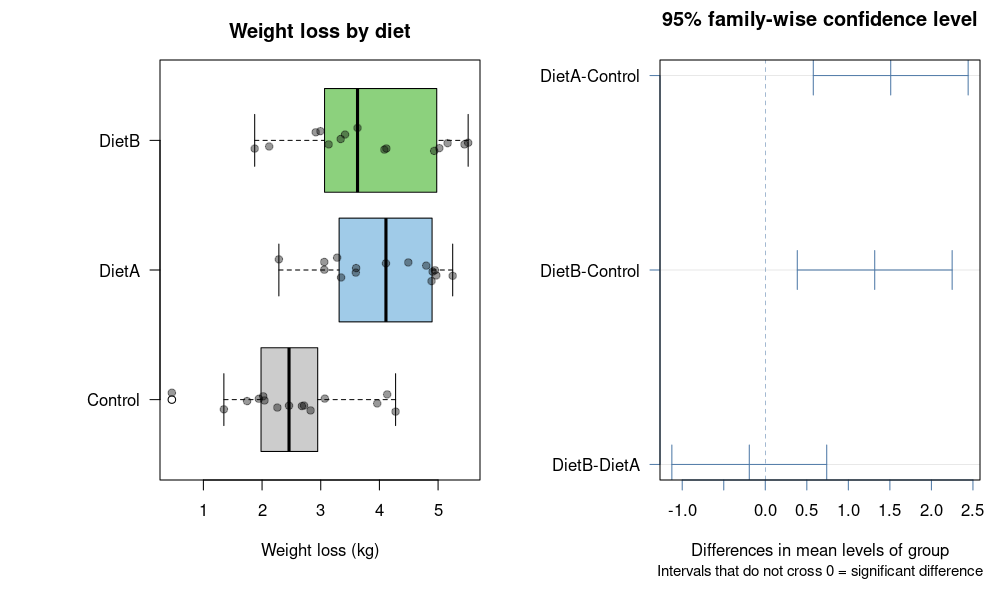

In [6]:
par(mfrow = c(1, 2), mar = c(6, 8, 3, 1))
boxplot(loss ~ group, data = diet, col = c("grey80", "#A0CBE8", "#8CD17D"), horizontal = TRUE, las = 1,
        main = "Weight loss by diet", xlab = "Weight loss (kg)", ylab = "")
stripchart(loss ~ group, data = diet, method = "jitter", pch = 19, col = adjustcolor("black", 0.4), add = TRUE)

plot(tukey, las = 1, col = "#4E79A7")
title(sub = "Intervals that do not cross 0 = significant difference", cex.sub = 0.9)

*Insight: Both diets beat the control, but the DietB–DietA interval crosses zero: these data can't tell the two diets apart. Reading the confidence intervals answers more than the p-values do — it also shows **how large** each difference plausibly is.*

## 5. Hundreds of Tests: Familywise Error vs False Discovery Rate

Bonferroni and Holm control the **familywise error rate (FWER)**: the chance of making *even one* false positive. With hundreds or thousands of tests (genes, A/B metrics, survey items) that is so strict that almost every real effect is missed.

The **false discovery rate (FDR)** controls a different quantity: the expected *share* of false positives among the results you call significant. The **Benjamini–Hochberg** procedure:

1. Sort the $m$ p-values: $p_{(1)} \le p_{(2)} \le \dots \le p_{(m)}$.
2. Find the largest $k$ with $p_{(k)} \le \frac{k}{m}\,q$ (e.g. $q = 0.05$).
3. Reject the hypotheses with the $k$ smallest p-values.

In R: `p.adjust(p, method = "BH")`.

           true_discoveries false_discoveries share_false
raw                      91                44       0.326
bonferroni                8                 0       0.000
holm                      8                 0       0.000
BH_fdr                   44                 0       0.000


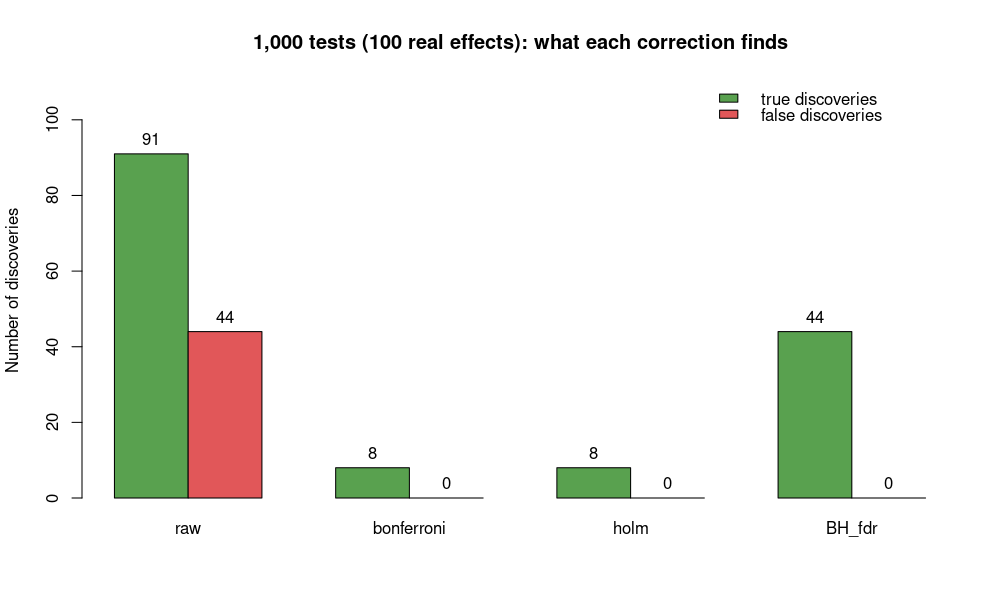

In [7]:
set.seed(18)
m_null <- 900; m_real <- 100
p_null <- replicate(m_null, t.test(rnorm(20), rnorm(20))$p.value)              # no effect
p_real <- replicate(m_real, t.test(rnorm(20), rnorm(20, mean = 1))$p.value)    # true effect, d = 1
p_all <- c(p_null, p_real)
is_real <- rep(c(FALSE, TRUE), c(m_null, m_real))

summarise <- function(p) {
  sig <- p < 0.05
  c(true_discoveries = sum(sig & is_real), false_discoveries = sum(sig & !is_real),
    share_false = round(sum(sig & !is_real) / max(1, sum(sig)), 3))
}
res <- rbind(raw = summarise(p_all),
             bonferroni = summarise(p.adjust(p_all, "bonferroni")),
             holm = summarise(p.adjust(p_all, "holm")),
             BH_fdr = summarise(p.adjust(p_all, "BH")))
print(res)

bp <- barplot(t(res[, c("true_discoveries", "false_discoveries")]), beside = TRUE,
              col = c("#59A14F", "#E15759"), ylim = c(0, 110),
              main = "1,000 tests (100 real effects): what each correction finds", ylab = "Number of discoveries",
              legend.text = c("true discoveries", "false discoveries"), args.legend = list(x = "topright", bty = "n"))
text(bp, t(res[, c("true_discoveries", "false_discoveries")]) + 4, t(res[, c("true_discoveries", "false_discoveries")]))

*Insight: Without correction you get dozens of false positives. Bonferroni removes almost all of them but also throws away many real effects. Benjamini–Hochberg finds more than five times as many real effects as Bonferroni (44 vs 8) and still keeps the share of false discoveries at or below the 5% target. Use FWER control (Holm) for a handful of planned comparisons, and FDR (BH) for large-scale screening.*

## 6. Step 3 — Effect Sizes

In [8]:
# Eta squared by hand from the ANOVA table
ss <- summary(anova_model)[[1]][["Sum Sq"]]
eta2_manual <- ss[1] / sum(ss)
cat("Eta squared (manual) :", round(eta2_manual, 3), "\n")
cat("Eta squared (rstatix):", round(eta_squared(anova_model), 3), "\n\n")

# Cohen's d by hand and with effsize
cohens_d <- function(x, y) {
  sp <- sqrt(((length(x) - 1) * var(x) + (length(y) - 1) * var(y)) / (length(x) + length(y) - 2))
  (mean(x) - mean(y)) / sp
}
g <- split(diet$loss, diet$group)
pairs <- combn(names(g), 2)
d_tbl <- data.frame(comparison = apply(pairs, 2, paste, collapse = " vs "),
                    cohens_d = apply(pairs, 2, function(p) round(cohens_d(g[[p[2]]], g[[p[1]]]), 2)))
d_tbl$magnitude <- cut(abs(d_tbl$cohens_d), c(0, 0.2, 0.5, 0.8, Inf),
                       labels = c("negligible", "small", "medium", "large"), right = FALSE)
print(d_tbl, row.names = FALSE)

if (!requireNamespace("effsize", quietly = TRUE)) install.packages("effsize")
library(effsize)
cohen.d(g$DietB, g$Control)

Eta squared (manual) : 0.304 


Eta squared (rstatix): 0.304 



       comparison cohens_d  magnitude
 Control vs DietA     1.53      large
 Control vs DietB     1.19      large
   DietA vs DietB    -0.18 negligible



Cohen's d

d estimate: 1.186205 (large)
95 percent confidence interval:
    lower     upper 
0.3751169 1.9972935 


## 7. Significance vs Importance

The simulation below holds a **tiny** true difference fixed (d = 0.05) and increases the sample size. The p-value eventually becomes "significant", but the effect size correctly stays tiny.

 n_per_group  p_value cohens_d
          50 3.22e-01    0.199
         200 7.29e-01    0.035
        1000 7.36e-01    0.015
        5000 6.29e-02    0.037
       20000 3.39e-05    0.041
       50000 1.45e-11    0.043


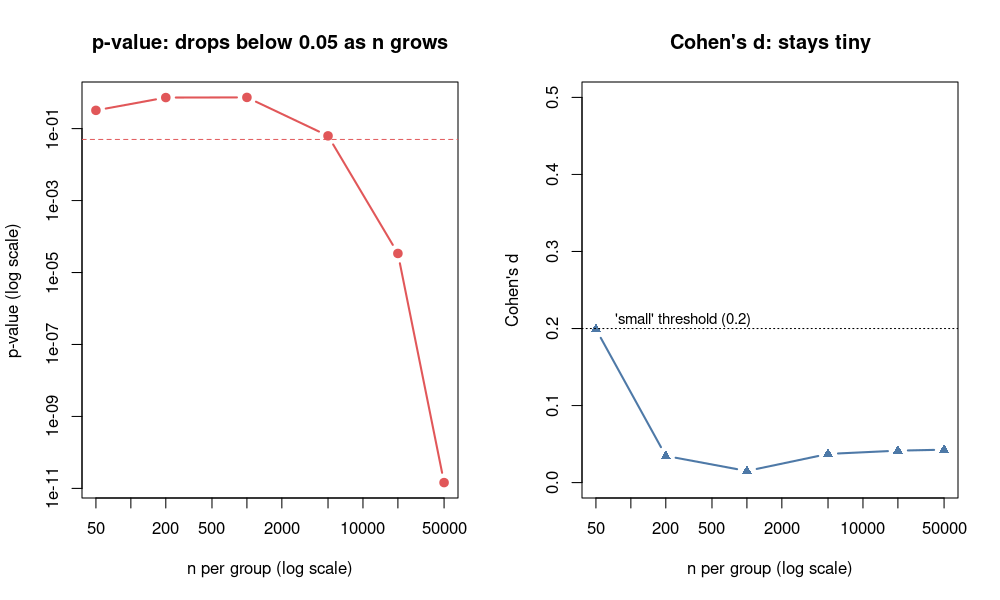

In [9]:
set.seed(170)
ns <- c(50, 200, 1000, 5000, 20000, 50000)
res <- t(sapply(ns, function(n) {
  x <- rnorm(n, 100, 15); y <- rnorm(n, 100.75, 15)   # true d = 0.05
  c(n = n, p_value = t.test(x, y)$p.value, cohens_d = abs(cohens_d(y, x)))
}))
print(data.frame(n_per_group = res[, "n"], p_value = signif(res[, "p_value"], 3),
                 cohens_d = round(res[, "cohens_d"], 3)), row.names = FALSE)

par(mfrow = c(1, 2))
plot(res[, "n"], res[, "p_value"], log = "xy", type = "b", pch = 19, lwd = 2, col = "#E15759",
     main = "p-value: drops below 0.05 as n grows", xlab = "n per group (log scale)", ylab = "p-value (log scale)")
abline(h = 0.05, lty = 2, col = "#E15759")
plot(res[, "n"], res[, "cohens_d"], log = "x", type = "b", pch = 17, lwd = 2, col = "#4E79A7", ylim = c(0, 0.5),
     main = "Cohen's d: stays tiny", xlab = "n per group (log scale)", ylab = "Cohen's d")
abline(h = 0.2, lty = 3); text(60, 0.21, "'small' threshold (0.2)", pos = 4, cex = 0.9)

*Insight: Always report an effect size **with** its p-value. "p < 0.001" with d = 0.05 means "we're very sure there's a difference, and it's too small to matter".*

## Real-World Use Case or Analogy

- **Post-hoc**: ANOVA is like a teacher saying, "Some groups scored differently." Post-hoc tests find **exactly which groups** differ.
- **Multiple-comparison correction**: if you buy 20 lottery tickets, one "winning" is less surprising than if you bought one. Corrections hold each comparison to a stricter standard because you made many.
- **Effect size**: a p-value tells you whether someone is taller; the effect size tells you **how many centimetres taller**.

A pharmaceutical company that finds a drug "significantly" lowers blood pressure by 0.5 mmHg in a 100,000-person trial has a real but clinically useless effect. Effect sizes keep decisions grounded in what actually matters.